# 0.0 Imports

In [22]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

# 0.1 Funções

# 0.2 Loading DataSet

In [2]:
df_raw = pd.read_excel('dataset/dataset_leite_fazenda_100_animais_900_dias.xlsx')

/home/lucas/.pyenv/versions/milk_env/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/home/lucas/.pyenv/versions/milk_env/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


In [3]:
#verificação shape do dataset
print(df_raw.shape)

#primeira cópia df_raw
df = df_raw.copy()

df.head(10).sort_values(by=['Date'], ascending=True).T

(6100, 49)


,0,1,2,3,4,5,6,7,8,9
Farm_ID,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001
Cattle_ID,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001
Date,2024-01-01 00:00:00,2024-01-16 00:00:00,2024-01-31 00:00:00,2024-02-15 00:00:00,2024-03-01 00:00:00,2024-03-16 00:00:00,2024-03-31 00:00:00,2024-04-15 00:00:00,2024-04-30 00:00:00,2024-05-15 00:00:00
Animal_Category,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow
Breed,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein
Country,BR,BR,BR,BR,BR,BR,BR,BR,BR,BR
State,MG,MG,MG,MG,MG,MG,MG,MG,MG,MG
Region,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast
Municipality,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa
Climate_Zone,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude


# 0.3 Baseline do Negócio

Quanto de CMS (Consumo de Matéria Seca) vai ser necessário para fornecer ao rebanho da fazenda nos próximos 180 dias.

boa previsão do leite -> boa previsão de consumo de MS -> investimento acertivo em volumoso -> economia de até 20% sobre o total da receita

CMS = (0,0185xPeso do animal) + (0,305xLitros do animal produzido)

In [4]:
# =================================================================
# Simulando da forma mais simples: CMS = peso_vivo * 0.03% parte 1
# =================================================================

"""
    Cada linha é uma coleta de dados no campo. Cada coleta são de 15 em 15 dias. 
    180 dias equivale a 12 observações em campo, ou 12 linhas do dataset.
"""

print('='*60)

#numero de animais
numero_de_vacas = df['Cattle_ID'].nunique()
print(f'Número de animais: {numero_de_vacas} vacas')

print('='*60)

#peso vivo dos animais por dia
peso_vivo_total_diario = df.groupby('Date')['Weight_kg'].sum()
print(f'Peso vivo total dos animais: {peso_vivo_total_diario:}kg')

print('='*60)

#rolling pega a linha 0 até a linha 11, ou seja, 12 datas/coletas
#peso vivo acumulado dos animais nos proximos 180 dias
peso_vivo_180d_total = peso_vivo_total_diario.rolling(12, min_periods=1).sum()
print(f'Peso vivo total acumulado dos animais dos proximos 180 dias somados: {peso_vivo_180d_total:}kg')

print('='*60)
#CMS de matéria seca diária (3% do PV)
CMS = df.groupby('Date')['Weight_kg'].sum()*0.03
print(f'Consumo de Matérica seca por peso vivo por dia: {CMS}kg')

print('='*60)

#Consumo de matéria seca acumulada nos proximos 180 dias
CMS_180d_total = CMS.rolling(12, min_periods=1).sum()
print(f'CMS acumulado dos proximos 180 dias somados: {CMS_180d_total:}kg')

print('='*60)

Número de animais: 100 vacas
Peso vivo total dos animais: Date
2024-01-01    59520.9
2024-01-16    59732.4
2024-01-31    59799.7
2024-02-15    59874.5
2024-03-01    59988.5
               ...   
2026-04-20    63254.3
2026-05-05    63192.5
2026-05-20    63150.9
2026-06-04    63277.7
2026-06-19    63212.8
Name: Weight_kg, Length: 61, dtype: float64kg
Peso vivo total acumulado dos animais dos proximos 180 dias somados: Date
2024-01-01     59520.9
2024-01-16    119253.3
2024-01-31    179053.0
2024-02-15    238927.5
2024-03-01    298916.0
                ...   
2026-04-20    759360.6
2026-05-05    759324.6
2026-05-20    759160.4
2026-06-04    759170.3
2026-06-19    759022.3
Name: Weight_kg, Length: 61, dtype: float64kg
Consumo de Matérica seca por peso vivo por dia: Date
2024-01-01    1785.627
2024-01-16    1791.972
2024-01-31    1793.991
2024-02-15    1796.235
2024-03-01    1799.655
                ...   
2026-04-20    1897.629
2026-05-05    1895.775
2026-05-20    1894.527
2026-06-04    18

In [5]:
# =================================================================
# Simulando da forma mais simples: CMS = peso_vivo * 0.03% parte 2
# =================================================================

#consumo de materia natural silagem proximos 180 dias (kg)
CMN_180d = CMS_180d_total / 0.3

#custo de materia natural silagem proximos 180 dias (R$/kg = 0,20 ) (R$)
custo_CMN_180d = CMN_180d * 0.2

#custo acumulado de materia natural silagem proximos 180 dias
custo_CMN_180d.sum()
print(f'custo com matéria natural nos próximos 180 dias é de R${custo_CMN_180d.sum():.2f}')

custo com matéria natural nos próximos 180 dias é de R$826651.44


# 1.0 Criando os Target e Pré-limpeza

In [6]:
print(df.isna().sum())
df.shape

df1 = df.copy()

#tirando as colunas que resolvemos não trabalhar
df1 = df1.drop(['Lag_Mean_180_Days', 'Target_Milk_15_Days', 'Target_Milk_30_Days', 'Target_Milk_90_Days', 
                'Farm_ID', 'Breed', 'Country', 'State', 'Region', 'Municipality', 'Management_System', 
                'Lot', 'Milking_Interval_hrs', 'Housing_Score', 'Grazing_Duration_hrs', 'Climate_Zone', 'Feed_Type', 'Lactation_Status'], axis=1)


Farm_ID                          0
Cattle_ID                        0
Date                             0
Animal_Category                  0
Breed                            0
Country                          0
State                            0
Region                           0
Municipality                     0
Climate_Zone                     0
Management_System                0
Feed_Type                        0
Season                           0
Age_Days                         0
Age_Months                       0
Weight_kg                        0
Parity                           0
Lactation_Status                 0
Lactation_Stage                  0
Days_in_Milk                     0
Days_Since_Calving               0
Lot                              0
Milking_Frequency_per_day        0
Milking_Interval_hrs             0
Body_Condition_Score             0
Body_Condition_Class             0
Ambient_Temperature_C            0
Humidity_percent                 0
Temperature_Humidity

In [7]:
#apagando as linhas que contém NaN 
df1 = df1.dropna(subset = ['Target_Milk_180_Days', 'Lag_Mean_90_Days'])

df1.shape

(4300, 31)

In [8]:
aux = df1.groupby('Cattle_ID')['Milk_Yield_L'].count()
aux

Cattle_ID
CATTLE_001    43
CATTLE_002    43
CATTLE_003    43
CATTLE_004    43
CATTLE_005    43
              ..
CATTLE_096    43
CATTLE_097    43
CATTLE_098    43
CATTLE_099    43
CATTLE_100    43
Name: Milk_Yield_L, Length: 100, dtype: int64

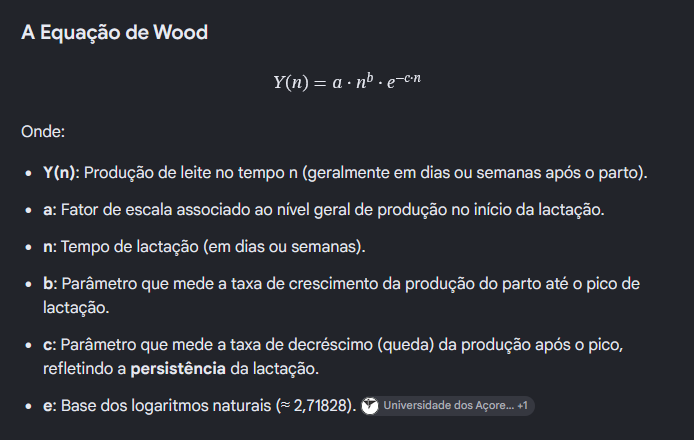

0-12 observações (TREINO)
13-24 (não posso usar)
25 - 30 (VAL) ->>>>> prever 42 <<<<<- 
31 - 36 (não posso usar)
37 - 43 (TESTE) ->>>> 55


10 dias de previsão

0-60 treino

71-80 val

85-100 teste

-----------                             produção real 20 Litros    target 75 = Milk_Yield_L 85            
 75 eu ja sei oq aconteceu no dia 85 -> meu treino ficou roubado
0-80 treino 

            MIlk_Yield_L: 20 litros
dia 85 -> produção real 20 Litros
85-100 teste ->> 95-110

# 2.0 Separação Treino, Test, Val e Target

In [9]:
#garantindo que as colunas sejam datas
df1['Date'].info()

#lista as datas distintas, em ordem
registros = df1['Date'].sort_values().unique()
registros

#os ultimos o primeiro registro do grupo de dados test, de trás pra frente
registros_test = registros[-7]
registros_test

X_train = df1.loc[(df1['Date'] < registros_test), :].copy()

X_test = df1.loc[(df1['Date'] >= registros_test), :].copy()

#treino e teste separados, ainda falta val e tirar as interseções

#=======================================================================================

#separando treino e val
aux_1 = X_train['Date'].sort_values().unique()
registros_train = aux_1[11]

X_val = X_train.loc[(X_train['Date'] > registros_train), :].reset_index(drop=True)

X_train = X_train.loc[(X_train['Date'] <= registros_train), :].reset_index(drop=True)

#=======================================================================================

#tirando um pedaço do inicio de val (12 posições) e um pedaço do final de val (6)
aux_2 = X_val['Date'].sort_values().unique()
registros_val = aux_2[11]

X_val = X_val.loc[(X_val['Date'] > registros_val), :].reset_index(drop=True)


aux_3 = X_val['Date'].sort_values().unique()
registros_val_2 = aux_3[-6]

X_val = X_val.loc[(X_val['Date'] < registros_val_2), :].reset_index(drop=True)

X_val['Date'].nunique()

<class 'pandas.Series'>
Index: 4300 entries, 6 to 6087
Series name: Date
Non-Null Count  Dtype         
--------------  -----         
4300 non-null   datetime64[us]
dtypes: datetime64[us](1)
memory usage: 67.2 KB


6

In [10]:
#separando X de y

y_train = X_train['Target_Milk_180_Days']
X_train = X_train.drop('Target_Milk_180_Days', axis=1)

y_test = X_test['Target_Milk_180_Days']
X_test = X_test.drop('Target_Milk_180_Days', axis=1)

y_val = X_val['Target_Milk_180_Days']
X_val = X_val.drop('Target_Milk_180_Days', axis=1)

In [ ]:
#verificando se as divisões foram corretas em relação a dimensão

print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)

print(X_val.shape)
print(y_val.shape)

(1200, 30)
(1200,)
(700, 30)
(700,)
(600, 30)
(600,)


In [13]:
#concantenando x e y train para fazer E.D.A

df_train = pd.concat([X_train, y_train], axis=1)

# 3.0 Analisando os Dados

In [14]:
#conferindo celulas vazias e duplicadas
print(df_train.isna().sum())
print(df_train.shape)
print(df_train.duplicated().sum())

Cattle_ID                     0
Date                          0
Animal_Category               0
Season                        0
Age_Days                      0
Age_Months                    0
Weight_kg                     0
Parity                        0
Lactation_Stage               0
Days_in_Milk                  0
Days_Since_Calving            0
Milking_Frequency_per_day     0
Body_Condition_Score          0
Body_Condition_Class          0
Ambient_Temperature_C         0
Humidity_percent              0
Temperature_Humidity_Index    0
Heat_Stress_Class             0
Health_Status                 0
Days_Since_Health_Event       0
Rumination_Time_hrs           0
Resting_Hours                 0
Water_Intake_L                0
Walking_Distance_km           0
Previous_Week_Avg_Yield       0
Milk_Yield_L                  0
Dry_Matter_Intake_kg          0
Lag_Mean_15_Days              0
Lag_Mean_30_Days              0
Lag_Mean_90_Days              0
Target_Milk_180_Days          0
dtype: i

# 4.0 Análise Descritiva

## 4.1 Variáveis Numéricas

In [15]:
#separando os dados numéricos
num_atributos = df_train.select_dtypes(include=['float64', 'int'])
num_atributos.T

,0,1,2,3,4,5,6,7,8,9,...,1190,1191,1192,1193,1194,1195,1196,1197,1198,1199
Age_Days,1097.00,1112.00,1127.00,1142.00,1157.00,1172.00,1187.00,1202.00,1217.00,1232.00,...,352.00,367.00,382.00,397.00,412.00,427.00,442.00,457.00,472.00,487.00
Age_Months,36.00,36.50,37.00,37.50,38.00,38.50,39.00,39.50,40.00,40.50,...,11.60,12.10,12.60,13.00,13.50,14.00,14.50,15.00,15.50,16.00
Weight_kg,619.60,617.90,619.00,628.30,624.50,629.60,619.10,620.20,604.00,593.00,...,371.80,365.00,377.60,389.70,392.50,401.80,406.80,418.90,434.50,435.20
Parity,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00,2.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Days_in_Milk,260.00,275.00,290.00,0.00,0.00,0.00,0.00,0.00,15.00,30.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Days_Since_Calving,260.00,275.00,290.00,305.00,320.00,335.00,350.00,365.00,15.00,30.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Milking_Frequency_per_day,3.00,3.00,3.00,0.00,0.00,0.00,0.00,0.00,3.00,3.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Body_Condition_Score,3.44,3.76,3.67,3.37,3.40,3.27,3.68,3.55,3.15,3.20,...,3.42,3.23,3.42,3.34,3.33,3.28,3.29,3.28,3.40,3.35
Ambient_Temperature_C,23.72,23.97,22.70,24.29,24.62,22.96,21.57,22.16,18.23,20.42,...,22.70,24.29,24.62,22.96,21.57,22.16,18.23,20.42,17.81,17.47
Humidity_percent,76.05,89.44,84.96,78.67,77.74,76.08,73.65,71.80,75.67,66.70,...,84.96,78.67,77.74,76.08,73.65,71.80,75.67,66.70,69.08,70.70


In [17]:
#tendencia central - média e mediana

ct1 = pd.DataFrame(num_atributos.mean()).T

ct2 = pd.DataFrame(num_atributos.median()).T

#dispersão: std, minimo, maximo, range, skewness, kurtosis

d1 = pd.DataFrame(num_atributos.std()).T
d2 = pd.DataFrame(num_atributos.min()).T
d3 = pd.DataFrame(num_atributos.max()).T
d4 = pd.DataFrame(num_atributos.max() - num_atributos.min()).T
d5 = pd.DataFrame(num_atributos.skew()).T
d6 = pd.DataFrame(num_atributos.kurtosis()).T

#concatenar os resultados
m = pd.concat([ct1, ct2, d1, d2, d3, d4, d5, d6], axis=0).T.reset_index()

#trocando nome das colunas
m.columns = ['atributos', 'mean', 'median', 'std', 'min', 'max', 'range', 'skew', 'kurtosis']
m.style.background_gradient(cmap='Blues')

#skew:
#-0.5 a 0.5: pouco assimetria
#-1 a -0,5: assimetrica moderadamente
#0.5 a 1: assimetrica moderadamente
#-1 < e > 1: assimetria forte

,atributos,mean,median,std,min,max,range,skew,kurtosis
0,Age_Days,1634.560000,1651.500000,660.429087,282.000000,2797.000000,2515.000000,-0.192298,-0.843483
1,Age_Months,53.702250,54.250000,21.697672,9.300000,91.900000,82.600000,-0.192437,-0.843509
2,Weight_kg,607.372417,628.250000,81.556840,327.400000,738.300000,410.900000,-1.235916,1.308511
3,Parity,2.443333,3.000000,1.423075,0.000000,5.000000,5.000000,-0.191321,-0.770640
4,Days_in_Milk,97.397500,71.000000,97.302086,0.000000,300.000000,300.000000,0.598008,-1.013171
5,Days_Since_Calving,151.042500,135.000000,118.719372,0.000000,365.000000,365.000000,0.261187,-1.297977
6,Milking_Frequency_per_day,1.750833,2.000000,1.214487,0.000000,3.000000,3.000000,-0.513228,-1.325061
7,Body_Condition_Score,3.353250,3.380000,0.236980,2.630000,4.010000,1.380000,-0.247915,-0.445687
8,Ambient_Temperature_C,21.660000,22.430000,2.483792,17.470000,24.620000,7.150000,-0.568358,-1.148973
9,Humidity_percent,75.878333,75.860000,6.171315,66.700000,89.440000,22.740000,0.698921,-0.062933


## 4.2 Variáveis Categóricas

In [20]:
cat_atributos = df_train.select_dtypes(exclude=['float64', 'int', 'datetime64'])

print(cat_atributos.columns)
print(cat_atributos.nunique())
cat_atributos.T

Index(['Cattle_ID', 'Animal_Category', 'Season', 'Lactation_Stage',
       'Body_Condition_Class', 'Heat_Stress_Class', 'Health_Status'],
      dtype='str')
Cattle_ID               100
Animal_Category           2
Season                    3
Lactation_Stage           5
Body_Condition_Class      3
Heat_Stress_Class         3
Health_Status             4
dtype: int64


,0,1,2,3,4,5,6,7,8,9,...,1190,1191,1192,1193,1194,1195,1196,1197,1198,1199
Cattle_ID,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,...,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100
Animal_Category,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,...,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer
Season,Autumn,Autumn,Autumn,Autumn,Autumn,Winter,Winter,Winter,Winter,Winter,...,Autumn,Autumn,Autumn,Winter,Winter,Winter,Winter,Winter,Winter,Spring
Lactation_Stage,Late,Late,Late,Dry,Dry,Dry,Dry,Dry,Early,Early,...,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation
Body_Condition_Class,ok,ok,ok,ok,ok,ok,ok,ok,ok,ok,...,ok,ok,ok,ok,ok,ok,ok,ok,ok,ok
Heat_Stress_Class,Moderate,Moderate,Mild,Moderate,Moderate,Mild,Mild,Mild,No_Stress,No_Stress,...,Mild,Moderate,Moderate,Mild,Mild,Mild,No_Stress,No_Stress,No_Stress,No_Stress
Health_Status,Healthy,Healthy,Healthy,Healthy,Lameness,Lameness,Healthy,Healthy,Healthy,Healthy,...,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy


## 4.3 Hipóteses

1. Vacas com estágio de lactação médio tem maior produtividade diários que vacas com estágio cedo e tardio
2. Vacas com idade mediana produz mais leite que as demais faixas de idade
3. Vacas mais pesadas tendem a produzir mais leite
4. Vacas com número de partos mediano produz mais leite que as demais faixas de numero de partos
5. Vacas que ingerem mais águas produzem mais litros leite diários
6. Vacas que andam mais, produzem menos litros de leite diários
7. Vacas que descansam mais tem mais produtividade litros de leite diários
8. Vacas no outono produzem mais litros de leite diariamente
9. Na maior parte das vezes, vacas com média diária da semana anterior com maiores produtividades, tendem a produzir maior litros de leite
10. Vacas com score corporal 3 tendem a ter maior produtividade diária
11. Vacas com intervalo de ordenha de 8h tendem a ter maior produtividade diária
12. Vacas saudáveis tendem a produzir mais litros de leite 

# 5.0 Análise Exploratória de Dados (E.D.A)

## 5.1 Análise Univariada

### 5.1.1 Análise Variável Resposta

<Axes: xlabel='Target_Milk_180_Days', ylabel='Count'>

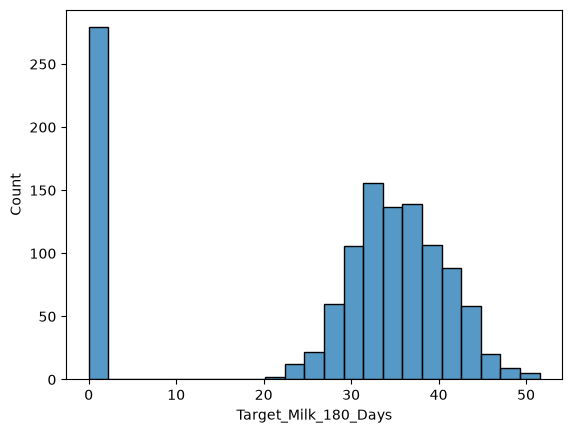

In [23]:
#analisando a variavel resposta

sns.histplot(data=df_train, x='Target_Milk_180_Days')

### 5.1.2 Análise Univariada Numéricas

## Análise Univariada Numérica (Regressão) — Explicação do Código

### Ideia geral

Na classificação, a pergunta era: **"a feature separa os grupos do alvo?"**. Na regressão o alvo é um número contínuo, então a pergunta passa a ser: **"quando a feature aumenta, o alvo aumenta, diminui ou não muda?"**

O código responde isso **para cada feature numérica, uma de cada vez**, e monta uma tabela ordenada da feature mais relacionada com o alvo até a menos relacionada.

---

### 1. Importações

```python
from sklearn.feature_selection import mutual_info_regression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score, KFold
```

- **`mutual_info_regression`**: calcula a Mutual Information (bloco 7).
- **`DecisionTreeRegressor`**: árvore de decisão para prever valores numéricos (bloco 8).
- **`cross_val_score`, `KFold`**: ferramentas da validação cruzada (blocos 3 e 8).
- `stats` (scipy), `np` e `pd` já foram importados no início do notebook.

---

### 2. Definir o alvo e a lista de features

```python
TARGET = 'nome_do_alvo'

num_cols = [c for c in df_train.select_dtypes(include=[np.number]).columns if c != TARGET]
```

- **`TARGET`**: nome da coluna que se quer prever.
- **`select_dtypes(include=[np.number])`**: seleciona só as colunas numéricas.
- **`if c != TARGET`**: remove o alvo da lista de features.

> **Por que remover o alvo:** na classificação, o alvo era texto ('Yes'/'No') e ficava fora do `select_dtypes` automaticamente. Na regressão o alvo é numérico e entraria na lista: seria comparado consigo mesmo, daria relação perfeita e apareceria em 1º lugar na tabela, sem significado nenhum.

---

### 3. Preparar a validação cruzada

```python
kf = KFold(n_splits=5, shuffle=True, random_state=42)
```

- **`n_splits=5`**: divide os dados em 5 partes.
- **`shuffle=True`**: embaralha antes de dividir, caso os dados estejam ordenados (por data, por animal).
- **`random_state=42`**: fixa o embaralhamento para que o resultado seja o mesmo a cada execução.

O objeto `kf` só é usado no bloco 8.

---

### 4. Criar os recipientes e iniciar o loop

```python
results = []
cache = {}

for col in num_cols:
```

- **`results`**: lista vazia. A cada feature analisada, recebe uma linha com os números dela. No final, vira a tabela.
- **`cache`**: dicionário que guarda os dados de cada feature para os gráficos da Parte 2, sem recalcular.
- **`for col in num_cols`**: repete os blocos 5 a 11 para cada feature. Na 1ª volta, `col` é a 1ª feature da lista; na 2ª volta, a 2ª; e assim por diante.

---

### 5. Separar os dados da feature da vez

```python
    series = df_train[col].dropna()
    pares  = df_train[[col, TARGET]].dropna()
    x, y   = pares[[col]], pares[TARGET]
```

- **`series`**: só a coluna da feature, sem valores vazios. Usada nas estatísticas que olham apenas a feature (média, desvio, outliers).
- **`pares`**: feature **e** alvo lado a lado. O `dropna` remove a linha inteira se faltar valor em qualquer uma das duas.
- **`x`**: a feature com colchete duplo `[[col]]`, para continuar sendo DataFrame. O sklearn exige o X nesse formato.
- **`y`**: o alvo com colchete simples, para ser uma Series (uma coluna só).

> **Por que remover os vazios das duas colunas juntas:** a correlação compara cada linha consigo mesma (o valor da feature do animal 5 com o alvo do animal 5). Removendo os vazios de cada coluna separadamente, os tamanhos ficariam diferentes e as linhas se desalinhariam.

---

### 6. Correlações e reta

```python
    try:
        pearson_r,  pearson_p  = stats.pearsonr(x[col], y)
        spearman_r, spearman_p = stats.spearmanr(x[col], y)
        slope, intercept = np.polyfit(x[col], y, 1)
    except Exception:
        pearson_r = pearson_p = spearman_r = spearman_p = slope = intercept = np.nan
```

A correlação é um número **de −1 a +1**:

| Valor | Significado |
|---|---|
| perto de **+1** | feature sobe → alvo sobe |
| perto de **−1** | feature sobe → alvo desce |
| perto de **0** | sem tendência clara |

- **`pearsonr` (Pearson)**: mede se os pontos formam uma **linha reta**. É sensível a outliers: um único valor extremo pode distorcer o resultado.
- **`spearmanr` (Spearman)**: substitui cada valor pela posição no ranking (o menor vira 1º, o seguinte 2º...) e compara os rankings. Mede se, quando um sobe, o outro **também sobe**, sem exigir linha reta. Como usa posições, é robusto a outliers.
- **`_p` (p-valor)**: probabilidade de aparecer uma correlação desse tamanho **por acaso**, se não houvesse relação real. Abaixo de 0,05 costuma indicar relação real. O p-valor diz se a relação **existe**, não se ela é **grande**.
- **`np.polyfit(..., 1)`**: ajusta a melhor reta pelos pontos (o `1` indica polinômio de grau 1, ou seja, uma reta).
  - **`slope`** (inclinação): quanto o alvo muda quando a feature aumenta 1 unidade.
  - **`intercept`**: onde a reta cruza o eixo vertical.
  - Os dois são usados só para desenhar a reta nos gráficos da Parte 2.
- **`try/except`**: se a feature for constante (todos os valores iguais), a correlação não existe e o cálculo falharia. O código grava `NaN` e segue para a próxima feature, em vez de interromper a análise.

> **Exemplo da tabela:** `Days_Since_Calving` teve Pearson = 0,35 e Spearman = 0,42 (quanto mais dias desde o parto, maior tende a ser o alvo). `Days_Since_Health_Event` teve Spearman = −0,09: o sinal negativo indica que o alvo tende a cair quando a feature sobe, mas a relação é fraca.

---

### 7. Mutual Information

```python
    mi = mutual_info_regression(x, y, random_state=42)[0]
```

- **O que mede**: se conhecer o valor da feature ajuda a adivinhar o alvo, **de qualquer forma**, não só "subindo junto" ou "descendo junto".
- **Escala**: 0 = não ajuda. Quanto maior, mais ajuda. Não tem um máximo fixo como a correlação.
- **`[0]`**: a função devolve uma lista com um valor por feature. Como há uma feature só, pega o primeiro.

> **Por que medir além da correlação:** pense no consumo de energia de uma casa em função da temperatura. No frio extremo, o aquecedor liga (consumo alto); no calor extremo, o ar-condicionado liga (consumo alto); no clima ameno, o consumo é baixo. O gráfico forma um **U**. A correlação dá perto de 0, porque a descida e a subida se cancelam, mas a temperatura claramente influencia o consumo. A Mutual Information capta essa relação.
>
> **Na prática:** correlação baixa com MI alta indica que vale olhar o gráfico da feature.

---

### 8. R² de uma árvore com validação cruzada

```python
    try:
        tree    = DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=42)
        r2_tree = cross_val_score(tree, x, y, cv=kf, scoring='r2').mean()
    except Exception:
        r2_tree = np.nan
```

O **R²** é a fração da variação do alvo que a feature consegue explicar, de 0 a 1. Exemplo: R² = 0,34 → a feature explica 34% das diferenças no alvo.

- **`DecisionTreeRegressor`**: divide a feature em faixas ("se a feature < 50, prevê 20; entre 50 e 120, prevê 30...") e assim consegue seguir curvas e degraus que uma reta não segue.
- **`max_depth=3`**: no máximo 3 níveis de divisão, o que mantém a árvore simples.
- **`min_samples_leaf=20`**: cada faixa final precisa de pelo menos 20 linhas, o que impede a árvore de criar uma faixa para um ou dois pontos isolados.
- **`cross_val_score(..., cv=kf)`**: treina a árvore em 4 das 5 partes e testa na parte restante, repetindo 5 vezes com uma parte de teste diferente a cada vez.
- **`.mean()`**: média das 5 notas de R².

> **Por que validação cruzada:** avaliada nos mesmos dados em que treinou, a árvore teria uma nota ilusoriamente alta, como um aluno que viu a prova antes. Testando em dados que ela não viu, a nota é honesta.
>
> **R² negativo** (ex.: `Temperature_Humidity_Index` = −0,009): a árvore previu **pior do que simplesmente usar a média do alvo** para todas as linhas. A feature sozinha não explica nada.

---

### 9. Contagem de outliers

```python
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR     = Q3 - Q1
    n_outliers = int(((series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)).sum())
    pct_outliers = n_outliers / len(series) * 100
```

Este bloco é igual ao da classificação, porque depende só da feature, não do alvo.

- **`Q1`, `Q3`**: valores abaixo dos quais estão 25% e 75% dos dados.
- **`IQR`**: distância entre Q1 e Q3, onde fica a "metade central" dos dados.
- **Outlier**: valor mais de 1,5 × IQR abaixo do Q1 ou acima do Q3.
- **`.sum()`**: cada linha vira True (é outlier) ou False, e True conta como 1. A soma dá o total de outliers.
- **`pct_outliers`**: o total convertido em porcentagem das linhas.

---

### 10. Registrar a linha da tabela

```python
    results.append({
        'Feature'          : col,
        'Mean'             : round(series.mean(), 2),
        'Std'              : round(series.std(), 2),
        'Skew'             : round(series.skew(), 2),
        'Pearson r'        : round(pearson_r, 4),
        'Pearson p-value'  : round(pearson_p, 4),
        'Spearman ρ'       : round(spearman_r, 4),
        'Spearman p-value' : round(spearman_p, 4),
        'R² Linear'        : round(pearson_r ** 2, 4),
        'R² Árvore (CV)'   : round(r2_tree, 4),
        'Mutual Info'      : round(mi, 4),
        'N Outliers'       : n_outliers,
        '% Outliers'       : round(pct_outliers, 2),
    })
```

- **`append`**: adiciona um dicionário à lista. Cada chave vira uma coluna da tabela.
- **`Mean`, `Std`**: média e desvio padrão da feature. Na classificação eram calculados por grupo; na regressão não há grupos.
- **`Skew`** (assimetria): 0 = distribuição simétrica; positivo = cauda longa para a direita (poucos valores muito altos); negativo = cauda para a esquerda. Ex.: `Days_Since_Health_Event` = 2,37 (muitos valores baixos e alguns muito altos).
- **`R² Linear`**: com uma única feature, o R² da reta é exatamente o Pearson ao quadrado, então não é preciso ajustar um modelo. Ex.: `Days_Since_Calving` com Pearson 0,3536 → 0,3536² ≈ 0,125.
- **`round(..., 4)`**: arredonda para 4 casas, só para a tabela ficar legível.

> **Leitura conjunta de R² Linear e R² Árvore:**
>
> | Situação | Leitura |
> |---|---|
> | Árvore ≈ Linear (ou menor) | relação praticamente em linha reta |
> | Árvore **bem maior** que Linear | relação curva: considerar transformar a feature ou usar modelos de árvore |
>
> Ex.: `Days_Since_Calving` tem R² Linear = 0,13 e R² Árvore = 0,78, ou seja, uma relação forte e não linear.

---

### 11. Guardar os dados para os gráficos

```python
    cache[col] = dict(
        x=x[col],
        y=y,
        slope=slope,
        intercept=intercept,
        pearson_r=pearson_r,
        spearman_r=spearman_r
    )
```

- **`cache[col]`**: cria uma "gaveta" com o nome da feature (ex.: `cache['Weight_kg']`).
- **Conteúdo**: os pontos (`x`, `y`), a reta (`slope`, `intercept`) e as correlações, para usar no título do gráfico.

Na classificação o cache guardava curvas de densidade por grupo e a curva ROC. Na regressão o gráfico natural é a **dispersão** (um ponto por linha) com a reta ajustada por cima.

---

### 12. Montar e ordenar a tabela

```python
df_analysis = pd.DataFrame(results).sort_values('Spearman ρ', key=abs, ascending=False, na_position='last')
```

Esta linha está **fora do loop** (sem recuo) e só roda depois que todas as features foram analisadas.

- **`pd.DataFrame(results)`**: transforma a lista de dicionários em tabela.
- **`sort_values('Spearman ρ', ...)`**: ordena pela correlação de Spearman.
- **`key=abs`**: ordena pelo **valor absoluto**, sem o sinal. Assim −0,41 fica acima de +0,23, porque uma relação negativa forte é tão útil quanto uma positiva. O sinal continua visível na tabela.
- **`ascending=False`**: do maior para o menor.
- **`na_position='last'`**: features com `NaN` (constantes) vão para o final.

---

### 13. Classificar a força da relação

```python
def classify(row):
    rho = abs(row['Spearman ρ'])
    if pd.isna(rho):
        return '⚪ Constante'
    elif rho >= 0.5:
        return '🟢 Forte'
    elif rho >= 0.3:
        return '🟡 Moderada'
    else:
        return '🔴 Fraca'

df_analysis['Associação'] = df_analysis.apply(classify, axis=1)
```

- **`classify(row)`**: recebe uma linha da tabela e devolve um rótulo.
- **`abs(...)`**: remove o sinal, porque −0,6 é tão forte quanto +0,6.
- **`pd.isna(rho)`**: valor vazio significa feature constante.
- **0,5 / 0,3**: linhas de corte convencionais (Cohen) para correlação. Servem como referência de triagem, não como regra rígida.
- **`.apply(classify, axis=1)`**: aplica a função linha por linha (`axis=1`) e cria a coluna nova.

---

### 14. Exibir o resultado

```python
print("=" * 80)
print("UNIVARIATE ANALYSIS SUMMARY (REGRESSION)")
print("=" * 80)
display(df_analysis)
```

- **`"=" * 80`**: repete o caractere 80 vezes, formando uma linha separadora.
- **`display`**: mostra a tabela formatada no notebook.

---

### Como ler a tabela final

1. **Spearman ρ**: a feature tem relação com o alvo? Qual a força (coluna Associação) e a direção (sinal)?
2. **R² Linear × R² Árvore**: a relação é uma reta ou uma curva?
3. **Mutual Info**: correlação baixa com MI alta indica uma relação não monotônica (ex.: em forma de U). Vale olhar o gráfico.
4. **Skew e % Outliers**: a feature precisa de tratamento (log, tratamento de extremos) antes de entrar num modelo linear?

> **Atenção:** "numérico" não significa "contínuo". Colunas com códigos numéricos (região 1–5, flags 0/1) entram nesta análise como se fossem medidas contínuas. Elas devem ser tratadas na análise univariada **categórica**.


In [25]:
# ======================================================================
# PARTE 1 — Análise Univariada (Regressão): Tabela Resumo + Cache
# ======================================================================
from sklearn.feature_selection import mutual_info_regression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score, KFold
from scipy import stats

TARGET = 'Target_Milk_180_Days'   # coluna contínua que você quer prever

num_cols = [c for c in df_train.select_dtypes(include=[np.number]).columns if c != TARGET]
kf = KFold(n_splits=5, shuffle=True, random_state=42)

results = []
cache = {}

for col in num_cols:
    series = df_train[col].dropna()
    pares  = df_train[[col, TARGET]].dropna()   # remove NaN da feature E do alvo juntos
    x, y   = pares[[col]], pares[TARGET]

    try:
        pearson_r,  pearson_p  = stats.pearsonr(x[col], y)
        spearman_r, spearman_p = stats.spearmanr(x[col], y)
        slope, intercept = np.polyfit(x[col], y, 1)
    except Exception:
        pearson_r = pearson_p = spearman_r = spearman_p = slope = intercept = np.nan

    mi = mutual_info_regression(x, y, random_state=42)[0]

    try:
        tree    = DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=42)
        r2_tree = cross_val_score(tree, x, y, cv=kf, scoring='r2').mean()
    except Exception:
        r2_tree = np.nan

    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR     = Q3 - Q1
    n_outliers = int(((series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)).sum())
    pct_outliers = n_outliers / len(series) * 100

    results.append({
        'Feature'          : col,
        'Mean'             : round(series.mean(), 2),
        'Std'              : round(series.std(), 2),
        'Skew'             : round(series.skew(), 2),
        'Pearson r'        : round(pearson_r, 4),
        'Pearson p-value'  : round(pearson_p, 4),
        'Spearman ρ'       : round(spearman_r, 4),
        'Spearman p-value' : round(spearman_p, 4),
        'R² Linear'        : round(pearson_r ** 2, 4),
        'R² Árvore (CV)'   : round(r2_tree, 4),
        'Mutual Info'      : round(mi, 4),
        'N Outliers'       : n_outliers,
        '% Outliers'       : round(pct_outliers, 2),
    })

    cache[col] = dict(
        x=x[col],
        y=y,
        slope=slope,
        intercept=intercept,
        pearson_r=pearson_r,
        spearman_r=spearman_r
    )

df_analysis = pd.DataFrame(results).sort_values('Spearman ρ', key=abs, ascending=False, na_position='last')

def classify(row):
    rho = abs(row['Spearman ρ'])
    if pd.isna(rho):
        return '⚪ Constante'
    elif rho >= 0.5:
        return '🟢 Forte'
    elif rho >= 0.3:
        return '🟡 Moderada'
    else:
        return '🔴 Fraca'

df_analysis['Associação'] = df_analysis.apply(classify, axis=1)

print("=" * 80)
print("UNIVARIATE ANALYSIS SUMMARY (REGRESSION)")
print("=" * 80)
display(df_analysis)


UNIVARIATE ANALYSIS SUMMARY (REGRESSION)


,Feature,Mean,Std,Skew,Pearson r,Pearson p-value,Spearman ρ,Spearman p-value,R² Linear,R² Árvore (CV),Mutual Info,N Outliers,% Outliers,Associação
5,Days_Since_Calving,151.04,118.72,0.26,0.3536,0.0000,0.4193,0.0000,0.1250,0.7823,0.6276,0,0.00,🟡 Moderada
7,Body_Condition_Score,3.35,0.24,-0.25,0.0846,0.0034,0.2700,0.0000,0.0072,0.0709,0.1346,1,0.08,🔴 Fraca
1,Age_Months,53.70,21.70,-0.19,0.3051,0.0000,0.2354,0.0000,0.0931,0.2871,0.3326,0,0.00,🔴 Fraca
0,Age_Days,1634.56,660.43,-0.19,0.3051,0.0000,0.2354,0.0000,0.0931,0.2898,0.3308,0,0.00,🔴 Fraca
2,Weight_kg,607.37,81.56,-1.24,0.3949,0.0000,0.2121,0.0000,0.1559,0.2720,0.2695,72,6.00,🔴 Fraca
10,Temperature_Humidity_Index,69.36,4.14,-0.48,0.0725,0.0120,0.1089,0.0002,0.0053,-0.0088,0.0000,0,0.00,🔴 Fraca
4,Days_in_Milk,97.40,97.30,0.60,0.0874,0.0024,0.1088,0.0002,0.0076,0.5999,0.4954,0,0.00,🔴 Fraca
9,Humidity_percent,75.88,6.17,0.70,0.0697,0.0158,0.1068,0.0002,0.0049,-0.0044,0.0000,100,8.33,🔴 Fraca
8,Ambient_Temperature_C,21.66,2.48,-0.57,0.0690,0.0168,0.1004,0.0005,0.0048,-0.0069,0.0000,0,0.00,🔴 Fraca
11,Days_Since_Health_Event,19.29,41.92,2.37,-0.0682,0.0182,-0.0865,0.0027,0.0046,-0.0014,0.0000,294,24.50,🔴 Fraca


## Análise Univariada (Regressão) — Interpretação dos Resultados

### Por que a maioria das features aparece como "Fraca"?

A primeira versão da coluna **Associação** foi classificada pelo **Spearman ρ**. O Spearman só capta relações **monotônicas**, em que o alvo sempre sobe ou sempre desce quando a feature aumenta. Neste dataset, as relações mais fortes **sobem e depois descem**, e por isso o Spearman as subestima.

A evidência está na própria tabela: comparando o R² da reta com o R² da árvore e a Mutual Information, aparecem features fortes que o Spearman classificou como fracas.

| Feature | Spearman ρ | R² Linear | R² Árvore (CV) | Mutual Info |
|---|---|---|---|---|
| Days_Since_Calving | 0,42 | 0,13 | **0,78** | **0,63** |
| Days_in_Milk | 0,11 | 0,01 | **0,60** | **0,50** |
| Lag_Mean_90_Days | 0,07 | 0,00 | 0,25 | 0,37 |
| Milk_Yield_L | −0,02 | 0,00 | 0,00 | 0,24 |

- **Days_Since_Calving** explica sozinha **78%** da variação do alvo quando a relação pode ser curva (árvore), contra 13% em linha reta. É a feature mais informativa do dataset, mas pelo Spearman aparecia só como "Moderada".
- **Days_in_Milk** tem ρ = 0,11 ("Fraca"), mas a árvore explica 60% da variação.

> **Regra de leitura:** quando o R² da árvore é muito maior que o R² linear, a relação existe, mas é **não linear**. Correlação perto de zero não significa ausência de relação; significa que a relação não é uma linha que só sobe ou só desce.

### A causa: o ciclo produtivo da vaca

No dataset, o intervalo entre partos é de 365 dias: cerca de 290 dias de lactação e cerca de 60 dias de período seco (produção zero). O alvo é a produção **no dia, 180 dias à frente**. Exemplo com três vacas:

| Hoje: dias desde o parto | Daqui a 180 dias | Produção no alvo |
|---|---|---|
| 0 (recém-parida) | 180 dias de lactação | média |
| 150 | 330 → **seca** | **zero** |
| 220 | 400 → novo parto, 35 dias de lactação | **alta** (perto do pico) |

Conforme `Days_Since_Calving` aumenta, o alvo **cai, zera e volta a subir**. Como tendência e contratendência se compensam, o Spearman fica baixo, embora a relação seja quase determinística.

O mesmo raciocínio explica **Milk_Yield_L** (ρ = −0,02) e as médias de produção passada (`Lag_Mean_*`). Uma vaca no pico hoje estará no fim da lactação ou seca daqui a 6 meses; uma vaca seca hoje terá parido e estará no pico. A produção atual contém informação sobre o futuro (MI = 0,24), mas não numa direção única.

### Features fracas de verdade

Temperatura, umidade, THI, consumo de água e distância caminhada têm ρ baixo **e** R² da árvore ≈ 0 **e** MI ≈ 0. Como as três medidas concordam, essas variáveis realmente não ajudam a prever a produção a 180 dias. Isso é coerente com um dataset sintético, em que a produção é gerada principalmente pelo ciclo de lactação.

> **p-valor ≠ força da relação.** Quase todas as features têm p-valor ≈ 0,0000, inclusive as fracas. O p-valor responde se **existe** relação, não se ela é **grande**. Com milhares de linhas, até uma correlação de 0,10 é estatisticamente significativa. Para medir a força, usar ρ, R² e Mutual Information.

### Correção da classificação

A coluna **Associação** passa a usar o **maior R²** entre a reta e a árvore. Assim, relações fortes são reconhecidas, sejam lineares ou curvas. Os cortes 0,25 e 0,09 são os mesmos da correlação (0,5 e 0,3), elevados ao quadrado.

```python
def classify(row):
    r2 = max(row['R² Linear'], row['R² Árvore (CV)'])
    if pd.isna(r2):
        return '⚪ Constante'
    elif r2 >= 0.25:
        return '🟢 Forte'
    elif r2 >= 0.09:
        return '🟡 Moderada'
    else:
        return '🔴 Fraca'

df_analysis['R² Máx'] = df_analysis[['R² Linear', 'R² Árvore (CV)']].max(axis=1)
df_analysis = df_analysis.sort_values('R² Máx', ascending=False)
df_analysis['Associação'] = df_analysis.apply(classify, axis=1)
```

- **`max(...)`**: usa a melhor das duas notas, a da reta ou a da curva.
- **`R² Máx`**: coluna usada para ordenar a tabela pela força real da relação.

Pelos valores da tabela, a nova classificação fica:

| Associação | Features (R² Máx) |
|---|---|
| 🟢 Forte | Days_Since_Calving (0,78), Days_in_Milk (0,60), Dry_Matter_Intake_kg (0,32), Age_Days (0,29), Age_Months (0,29), Weight_kg (0,27), Lag_Mean_90_Days (0,25) |
| 🟡 Moderada | Parity (0,18) |
| 🔴 Fraca | Demais features, incluindo todas as variáveis climáticas |

### Pontos de atenção para a modelagem

- **Age_Months e Age_Days são a mesma informação** em unidades diferentes (ρ e R² linear idênticos: 0,2354 e 0,0931). Manter só uma no modelo.
- **Previous_Week_Avg_Yield e Lag_Mean_15_Days** têm valores quase iguais. Verificar se são redundantes antes de usar as duas.
- **As relações principais são não lineares**, então modelos baseados em árvore (Random Forest, Gradient Boosting) tendem a aproveitar melhor as features de ciclo do que uma regressão linear. Para usar um modelo linear, seria preciso transformar essas features (por exemplo, criar a variável "dias de lactação daqui a 180 dias").


### 5.1.3 Análise Univariada Categóricas

## 5.2 Análise Variável Bivariada

## 5.3 Análise Multivariada

### 5.3.1 Multivariada Numérica

### 5.3.2 Multivariada Categórica